# Встреча 1. Стоит ли тестировать: теория

> **Время:** 35 минут · **Дальше:** `practice.ipynb` · **Полная версия лекции:** `lesson.ipynb`

Вопрос встречи: стоит ли запускать A/B-тест нового чекаута, и с какими $\alpha$ и $n$ он принесёт больше денег. Дефолт «$\alpha = 0.05$, мощность 80%, MDE на глаз» не знает ни затрат, ни выручки. Строим финансовую модель решения (Georgiev, *Statistical Methods in Online A/B Testing*, гл. 11) и выбираем дизайн по ожидаемой прибыли.

| Блок | Тезис | Минут |
| --- | --- | :---: |
| 1 | Окупается только эффект выше точки безубыточности | 8 |
| 2 | Решаем против точки безубыточности; вероятность внедрения задают $n$ и сплит | 10 |
| 3 | Оптимальные $\alpha$ и $n$ ищем по деньгам и сравниваем со стандартом | 8 |
| 4 | $\alpha = 0.5$ — не монетка | 9 |

### Библиотеки

In [1]:
from dataclasses import dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm

try:  # слайдеры необязательны: без ipywidgets ноутбук исполняется целиком
    from ipywidgets import FloatSlider, IntSlider, interact
except ImportError:
    interact = None

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'
DATA = Path('../data/checkout_ab.csv')


def spaced(value: float) -> str:
    """Форматирует число с пробелами между разрядами."""
    return f'{value:,.0f}'.replace(',', ' ')

### Модель

Те же функции, что в `lesson.ipynb` и `practice.ipynb`: параметры кейса, вероятность внедрения, деньги дизайна, сетка и симуляция. На встрече ячейку можно не разбирать — формулы ниже по тексту.

In [2]:
@dataclass
class BusinessCase:
    """Параметры кейса «новый чекаут». Суммы в рублях, эффекты — относительные."""
    baseline_cr: float = 0.70              # конверсия чекаута в группе A
    daily_users: int = 7_500               # пользователей в день доходят до чекаута
    share_b: float = 0.20                  # доля трафика на новый вариант
    weekly_revenue: float = 137_000_000    # ARPU группы A ≈ 2 605 ₽ × 52 500 пользователей в неделю
    fixed_test_cost: float = 3_000_000     # подготовка и проведение теста
    implementation_cost: float = 10_000_000  # раскатка на 100% трафика
    rollback_cost: float = 5_000_000       # откат на старый чекаут
    monthly_maintenance: float = 1_000_000   # поддержка нового чекаута, пока он работает
    horizon_months: float = 12             # горизонт от старта теста
    monitoring_weeks: float = 4            # сколько недель после раскатки смотрим на дашборд
    rollback_threshold: float = -0.015     # падение, которое дашборд замечает без контроля

    @property
    def weekly_users(self) -> float:
        return self.daily_users * 7

    @property
    def horizon_weeks(self) -> float:
        return self.horizon_months * 52 / 12

    @property
    def weekly_maintenance(self) -> float:
        return self.monthly_maintenance * 12 / 52

    @property
    def maintenance_cost(self) -> float:
        return self.monthly_maintenance * self.horizon_months

    @property
    def break_even(self) -> float:
        """Эффект, при котором выручка за горизонт покрывает тест, внедрение и поддержку."""
        costs = self.fixed_test_cost + self.implementation_cost + self.maintenance_cost
        return costs / (self.weekly_revenue * self.horizon_weeks)

    @property
    def break_even_sunk(self) -> float:
        """Та же точка без затрат на тест: к моменту решения они уже потрачены."""
        costs = self.implementation_cost + self.maintenance_cost
        return costs / (self.weekly_revenue * self.horizon_weeks)

    def test_weeks(self, n_b):
        """Длительность теста: группа B набирает n_b пользователей при доле share_b."""
        return np.asarray(n_b, dtype=float) / (self.share_b * self.weekly_users)


def implementation_probability(p_control, relative_effect, break_even_effect, n_b, alpha=0.05, share_b=0.2):
    """Вероятность внедрения: оценка разницы выше порога delta_BE + z_{1-alpha} * SE. Сплит share_b, n_A = n_b (1 - s) / s."""
    n_b = np.asarray(n_b, dtype=float)
    n_a = n_b * (1 - share_b) / share_b
    p_true = np.clip(p_control * (1 + relative_effect), 1e-6, 1 - 1e-6)
    delta_true = p_true - p_control
    delta_be = p_control * break_even_effect
    se = np.sqrt(p_control * (1 - p_control) / n_a + p_true * (1 - p_true) / n_b)
    return norm.sf(norm.ppf(1 - alpha) - (delta_true - delta_be) / se)


def evaluate_design(case, effect_grid, density, n_b, alpha, break_even=None):
    """
    Выгоды и затраты с поправкой на риск для дизайна (n_b, alpha).

    break_even — порог решения (по умолчанию case.break_even; 0 — «стандартная» проверка против нуля).
    n_b и alpha можно передать массивами: ось эффектов всегда последняя.
    """
    threshold = case.break_even if break_even is None else break_even
    probability = implementation_probability(case.baseline_cr, effect_grid, threshold, n_b, alpha, case.share_b)

    test_weeks = case.test_weeks(n_b)
    post_weeks = np.maximum(case.horizon_weeks - test_weeks, 0)   # длинный тест откладывает внедрение
    watch_weeks = np.minimum(case.monitoring_weeks, post_weeks)    # мониторинг после раскатки
    rest_weeks = post_weeks - watch_weeks                          # остаток горизонта
    keep = effect_grid >= case.rollback_threshold                  # падение ниже порога видно и откатывается
    live_weeks = watch_weeks + rest_weeks * keep                   # сколько недель вариант работает

    test_value = case.share_b * case.weekly_revenue * effect_grid * test_weeks   # 20% трафика во время теста
    live_value = case.weekly_revenue * effect_grid * live_weeks
    decision_costs = (case.implementation_cost + case.weekly_maintenance * live_weeks
                      + case.rollback_cost * (~keep))

    gains = (np.maximum(test_value, 0) + np.maximum(live_value, 0) * probability) * density
    losses = (np.maximum(-test_value, 0) + (np.maximum(-live_value, 0) + decision_costs) * probability) * density

    expected_gain = np.trapezoid(gains, effect_grid, axis=-1)
    expected_loss = case.fixed_test_cost + np.trapezoid(losses, effect_grid, axis=-1)
    return {
        'probability': probability,
        'gains': gains,
        'losses': losses,
        'expected_gain': expected_gain,
        'expected_loss': expected_loss,
        'rr': expected_gain / expected_loss,
        'net': expected_gain - expected_loss,
    }


def ship_without_test(case, effect_grid, density):
    """Внедрить сразу: нет затрат на тест и задержки, но мониторинг и откат те же."""
    keep = effect_grid >= case.rollback_threshold
    live_weeks = case.monitoring_weeks + (case.horizon_weeks - case.monitoring_weeks) * keep
    profit = (case.weekly_revenue * effect_grid * live_weeks - case.implementation_cost
              - case.weekly_maintenance * live_weeks - case.rollback_cost * (~keep))
    return np.trapezoid(profit * density, effect_grid)



PRIOR_MU, PRIOR_SIGMA = 0.0, 0.015
effect_grid = np.linspace(-0.12, 0.12, 2401)   # одна сетка эффектов на весь ноутбук


def prior_density(mu: float = PRIOR_MU, sigma: float = PRIOR_SIGMA) -> np.ndarray:
    """Нормальное распределение ожиданий на сетке; сетка обрезает хвосты, поэтому нормируем заново."""
    weights = norm.pdf(effect_grid, mu, sigma)
    return weights / np.trapezoid(weights, effect_grid)


density = prior_density()


alpha_grid = np.array([0.01, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.8])
n_grid = np.unique(np.round(np.geomspace(1_000, 300_000, 60), -2)).astype(int)   # n_B: от 0.7 дня до 200 дней


def design_grid(case: BusinessCase, weights: np.ndarray = None, break_even: float = None) -> dict:
    """Считает RR и прибыль для всех сочетаний alpha и n_B."""
    weights = density if weights is None else weights
    return evaluate_design(case, effect_grid, weights, n_grid[None, :, None], alpha_grid[:, None, None], break_even)


def best_design(grid: dict, metric: str) -> tuple:
    """Находит alpha и n_B с максимальным значением метрики."""
    row, column = np.unravel_index(np.argmax(grid[metric]), grid[metric].shape)
    return alpha_grid[row], n_grid[column], grid['rr'][row, column], grid['net'][row, column]


def plot_design_maps(grid: dict, marks: dict = None, title: str = None) -> None:
    """Рисует тепловые карты RR и прибыли на сетке alpha и n_B."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), sharey=True)
    panels = [(axes[0], grid['rr'], 1, 'RR', 'rr'), (axes[1], grid['net'] / 1e6, 0, 'Чистая прибыль, млн ₽', 'net')]

    for ax, values, center, label, metric in panels:
        low, high = values.min(), values.max()
        if not low < center < high:
            low, high = min(low, center - 1e-6), max(high, center + 1e-6)
        mesh = ax.pcolormesh(n_grid, np.arange(alpha_grid.size), values, cmap='RdBu', shading='nearest',
                             norm=TwoSlopeNorm(vmin=low, vcenter=center, vmax=high))
        fig.colorbar(mesh, ax=ax, label=label)
        ax.contour(n_grid, np.arange(alpha_grid.size), values, levels=[center], colors='black', linewidths=1.5)

        best_alpha, best_n, *_ = best_design(grid, metric)
        ax.scatter(best_n, np.searchsorted(alpha_grid, best_alpha), marker='*', s=340, color='#EDB120',
                   edgecolor='black', zorder=4, label=f'Оптимум: α = {best_alpha}, n_B = {spaced(best_n)}')
        for name, (mark_alpha, mark_n) in (marks or {}).items():
            ax.scatter(mark_n, np.searchsorted(alpha_grid, mark_alpha), marker='o', s=110, color='white',
                       edgecolor='black', zorder=4, label=name)
        ax.set_xscale('log')
        ax.set_xlabel('Размер группы B, n_B (логарифмическая шкала)')
        ax.legend(loc='lower left', fontsize=10)
        ax.grid(False)

    axes[0].set_yticks(np.arange(alpha_grid.size), alpha_grid)
    axes[0].set_ylabel('Уровень значимости α, односторонний')
    if title:
        fig.suptitle(title, x=0.01, ha='left')
    plt.tight_layout()
    plt.show()


def simulate_design(case: BusinessCase, n_b: int, alpha: float, break_even: float = None,
                    n_sims: int = 400_000, seed: int = 42) -> tuple:
    """Оценивает среднюю прибыль дизайна полным разыгрыванием экспериментов."""
    rng = np.random.default_rng(seed)
    threshold = case.break_even if break_even is None else break_even
    theta = rng.normal(PRIOR_MU, PRIOR_SIGMA, n_sims)
    theta = theta[np.abs(theta) <= effect_grid.max()]   # та же область интегрирования, что и в формулах

    n_a = int(round(n_b * (1 - case.share_b) / case.share_b))
    p_control = case.baseline_cr
    control = rng.binomial(n_a, p_control, theta.size) / n_a
    treatment = rng.binomial(n_b, p_control * (1 + theta)) / n_b
    se = np.sqrt(control * (1 - control) / n_a + treatment * (1 - treatment) / n_b)
    ship = (treatment - control - p_control * threshold) / se > norm.ppf(1 - alpha)

    # Деньги по шагам: тест -> (если внедрили) мониторинг -> откат или работа до конца горизонта
    test_weeks = n_b / (case.share_b * case.weekly_users)
    watch = min(case.monitoring_weeks, case.horizon_weeks - test_weeks)
    rest = case.horizon_weeks - test_weeks - watch
    rolled_back = theta < case.rollback_threshold

    profit = case.share_b * case.weekly_revenue * theta * test_weeks - case.fixed_test_cost
    after_ship = np.where(
        rolled_back,
        (case.weekly_revenue * theta - case.weekly_maintenance) * watch - case.rollback_cost,
        (case.weekly_revenue * theta - case.weekly_maintenance) * (watch + rest),
    ) - case.implementation_cost
    profit += ship * after_ship
    return profit.mean(), profit.std() / np.sqrt(theta.size)

## Кейс: новый чекаут

Тот же кейс, что в датасете `data/checkout_ab.csv` и на встречах 2, 3 и 6. Конверсия чекаута в заказ — 70%, до чекаута доходит ~7 500 пользователей в день, новый вариант получает 20% трафика. Выручку за неделю берём из данных: средняя выручка пользователя группы A × 52 500 пользователей.

In [3]:
df = pd.read_csv(DATA)
users = df.drop_duplicates('user_id')            # дубли и «двойные» пользователи — тема встречи 3, здесь они почти не влияют
daily_users = users['user_id'].nunique() / users['date'].nunique()
arpu_a = users.loc[users['group'] == 'A', 'revenue'].mean()
weekly_revenue = round(arpu_a * 7_500 * 7, -6)

print(f"Пользователей в день: {daily_users:,.0f}".replace(',', ' '))
print(f"Доля B: {(users['group'] == 'B').mean():.3f}; конверсия A: {users.loc[users['group'] == 'A', 'converted'].mean():.3f}")
print(f"ARPU группы A: {arpu_a:,.0f} ₽".replace(',', ' '))
print(f"Выручка за неделю: {spaced(arpu_a * 7_500 * 7)} ₽, округлённо {spaced(weekly_revenue)} ₽")
assert weekly_revenue == BusinessCase().weekly_revenue

case = BusinessCase()

Пользователей в день: 7 501
Доля B: 0.201; конверсия A: 0.699
ARPU группы A: 2 605 ₽
Выручка за неделю: 136 739 779 ₽, округлённо 137 000 000 ₽


Затраты — оценка команды:

| Статья | Сумма | Когда платим |
| --- | ---: | --- |
| Тест: разработка второй версии, QA, аналитика | 3 млн ₽ | всегда |
| Внедрение на 100% трафика: интеграции с платёжками, нагрузка | 10 млн ₽ | если внедрили |
| Поддержка нового чекаута | 1 млн ₽ в месяц | пока он работает |
| Откат на старый чекаут | 5 млн ₽ | если откатили |

Горизонт — 12 месяцев от старта теста. Относительный рост конверсии даёт такой же относительный рост выручки.

**Ожидания.** Истинный эффект $\theta$ (относительный) заранее неизвестен. Берём $\theta \sim N(0,\ 1.5\%)$: чекаут уже конвертирует 70%, и правки страницы обычно двигают конверсию на доли процентного пункта. При $\sigma = 1.5\%$ 95% эффектов лежат в $\pm 3\%$, то есть в $\pm 2$ п.п. Среднее 0: хорошие и плохие варианты заранее равновероятны. Как оценить $\sigma$ по истории тестов — дополнительное задание практики.

## Блок 1. Точка безубыточности

**Тезис.** Тест окупается, только если эффект выше точки безубыточности (break-even, BE): выручка за горизонт должна покрыть тест, внедрение и поддержку.

$$
\theta_{BE} = \frac{C_{test} + C_{impl} + C_{maint}}{W \cdot H}
$$

где $W$ — выручка за неделю, $H$ — горизонт в неделях.

Фиксированные затраты: 25 000 000 ₽ на выручку 7 124 000 000 ₽ за год
Точка безубыточности: 0.351% относительных = 0.25 п.п.
Без затрат на тест (они уже потрачены к моменту решения): 0.309%


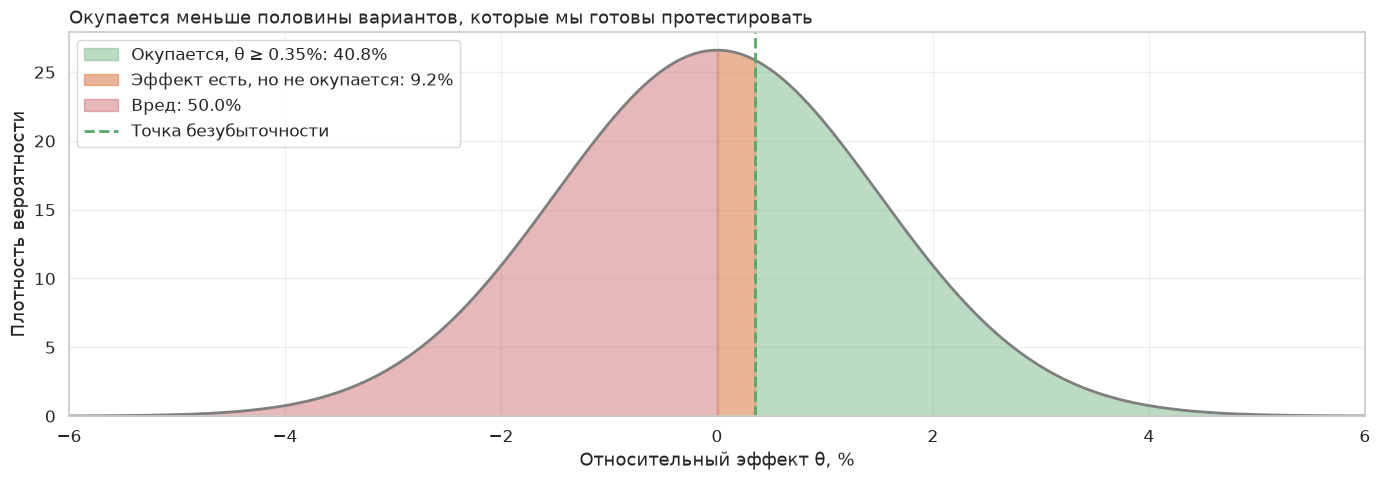

In [4]:
costs = case.fixed_test_cost + case.implementation_cost + case.maintenance_cost
prior = norm(PRIOR_MU, PRIOR_SIGMA)
print(f"Фиксированные затраты: {spaced(costs)} ₽ на выручку {spaced(case.weekly_revenue * case.horizon_weeks)} ₽ за год")
print(f"Точка безубыточности: {case.break_even:.3%} относительных = {case.break_even * case.baseline_cr * 100:.2f} п.п.")
print(f"Без затрат на тест (они уже потрачены к моменту решения): {case.break_even_sunk:.3%}")

x = effect_grid * 100
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(x, density, color=GRAY, linewidth=2)
ax.fill_between(x, density, where=effect_grid >= case.break_even, color=GREEN, alpha=0.4,
                label=f'Окупается, θ ≥ {case.break_even:.2%}: {prior.sf(case.break_even):.1%}')
ax.fill_between(x, density, where=(effect_grid > 0) & (effect_grid < case.break_even), color=ORANGE, alpha=0.6,
                label=f'Эффект есть, но не окупается: {prior.cdf(case.break_even) - prior.cdf(0):.1%}')
ax.fill_between(x, density, where=effect_grid <= 0, color=RED, alpha=0.4, label=f'Вред: {prior.cdf(0):.1%}')
ax.axvline(case.break_even * 100, color=GREEN, linestyle='--', linewidth=2, label='Точка безубыточности')
ax.set_title('Окупается меньше половины вариантов, которые мы готовы протестировать', loc='left')
ax.set_xlabel('Относительный эффект θ, %')
ax.set_ylabel('Плотность вероятности')
ax.set_xlim(-6, 6)
ax.set_ylim(bottom=0)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

Точка безубыточности — 0.35%, или 0.25 п.п. конверсии: меньше, чем шум двухнедельного теста. Она мала, потому что затраты (25 млн ₽) малы против выручки за год (7.1 млрд ₽). Но 9% вариантов попадают в зону «эффект положительный, но не окупается», и ещё половина вредна. Отличать их и есть работа теста.

## Блок 2. Решение против точки безубыточности

**Тезис.** Внедряем, если оценка эффекта уверенно выше BE, а не выше нуля:

$$
H_0:\ \theta \le \theta_{BE}, \qquad \text{внедряем, если}\ \ \hat\delta > \delta_{BE} + z_{1-\alpha}\cdot SE, \qquad SE = \sqrt{\frac{p_A(1-p_A)}{n_A} + \frac{p_B(1-p_B)}{n_B}}
$$

Здесь $\alpha$ односторонний: это вероятность внедрения при $\theta = \theta_{BE}$. Привычный двусторонний 0.05 — это односторонний 0.025. Сплит 80/20 даёт $n_A = 4 n_B$, а длительность теста задаёт меньшая группа: $T = n_B / (0.2 \cdot 52\,500)$ недель.

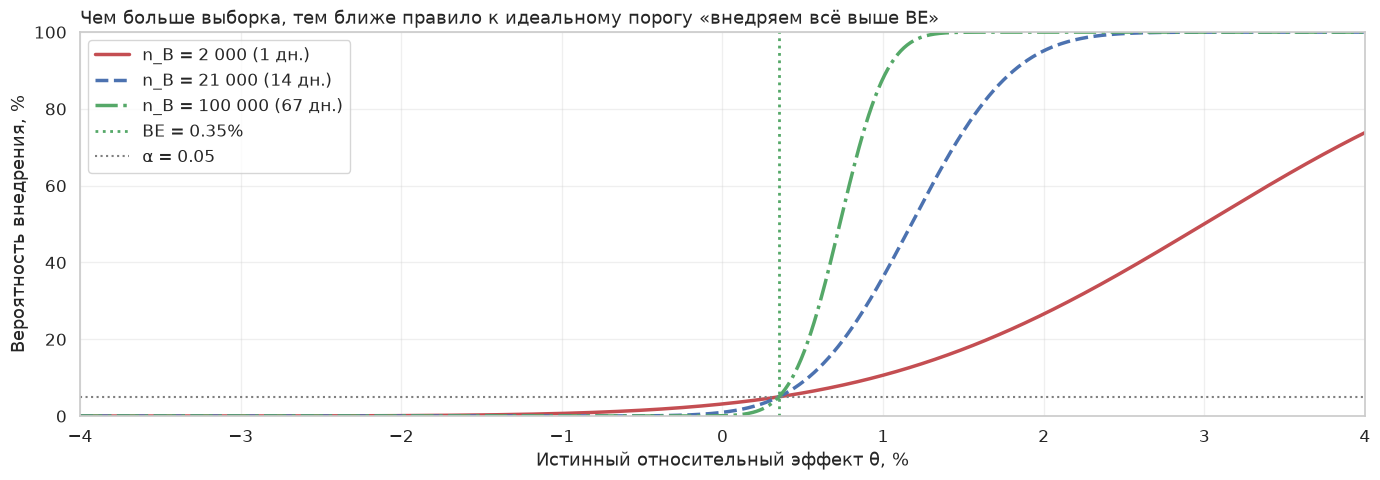

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
for n_b, color, style in [(2_000, RED, '-'), (21_000, BLUE, '--'), (100_000, GREEN, '-.')]:
    probability = implementation_probability(case.baseline_cr, effect_grid, case.break_even, n_b, 0.05, case.share_b)
    ax.plot(effect_grid * 100, probability * 100, color=color, linestyle=style, linewidth=2.5,
            label=f'n_B = {spaced(n_b)} ({case.test_weeks(n_b) * 7:.0f} дн.)')
ax.axvline(case.break_even * 100, color=GREEN, linestyle=':', linewidth=2, label=f'BE = {case.break_even:.2%}')
ax.axhline(5, color=GRAY, linestyle=':', linewidth=1.5, label='α = 0.05')
ax.set_title('Чем больше выборка, тем ближе правило к идеальному порогу «внедряем всё выше BE»', loc='left')
ax.set_xlabel('Истинный относительный эффект θ, %')
ax.set_ylabel('Вероятность внедрения, %')
ax.set_xlim(-4, 4)
ax.set_ylim(0, 100)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

Все кривые проходят через точку $(\theta_{BE},\ \alpha)$. При $n_B = 21\,000$ (две недели) вариант на $+2\%$ внедряется с вероятностью 95%, а вариант на $-1\%$ — почти никогда. При $n_B = 2\,000$ кривая пологая: тест почти ничего не решает.

**Деньги одного решения.** Дизайн $(n_B, \alpha)$ даёт ожидаемую прибыль

$$
\text{Net} = \int \pi(\theta)\Big[\,0.2\,W\theta T \;+\; POW(\alpha;\theta)\cdot\big(W\theta\,\ell(\theta) - C_{impl} - m\,\ell(\theta) - C_{rb}\,\mathbb 1[\theta < \theta_{RB}]\big)\Big]d\theta \;-\; C_{test}
$$

* $0.2\,W\theta T$ — вариант B во время теста видят 20% пользователей;
* $POW(\alpha;\theta)$ — вероятность внедрения; $m$ — поддержка в неделю;
* $\ell(\theta)$ — сколько недель вариант работает после внедрения. Первые $L = 4$ недели смотрим на дашборд. Без контрольной группы видно только крупное падение: $\theta < \theta_{RB} = -1.5\%$ (≈1 п.п.). Такой вариант откатываем: $\ell = L$, платим потери за 4 недели и 5 млн ₽ отката. Остальные работают до конца горизонта: $\ell = H - T$.

Правило согласовано: откат обрывает и потери, и выгоду, а мелкий вред ($-1.5\% < \theta < 0$) мониторинг не ловит — его отсекает только тест. Проверим формулу честной симуляцией: разыгрываем $\theta$ из ожиданий, конверсии групп, правило внедрения, откат и деньги.

In [6]:
for n_b, alpha in [(2_000, 0.05), (21_000, 0.5)]:
    formula = evaluate_design(case, effect_grid, density, n_b, alpha)['net']
    simulated, error = simulate_design(case, n_b, alpha)
    print(f"n_B = {spaced(n_b)}, α = {alpha}: формула {formula / 1e6:.2f} млн ₽, симуляция {simulated / 1e6:.2f} ± {1.96 * error / 1e6:.2f} млн ₽")
    assert abs(formula - simulated) < 3 * error, 'Формула и симуляция разошлись'

n_B = 2 000, α = 0.05: формула 6.53 млн ₽, симуляция 6.56 ± 0.12 млн ₽
n_B = 21 000, α = 0.5: формула 26.03 млн ₽, симуляция 26.05 ± 0.17 млн ₽


## Блок 3. Оптимальные $\alpha$ и $n$

**Тезис.** Перебираем сетку $\alpha \times n_B$ и берём дизайн с максимальной прибылью. Длинный тест точнее, но откладывает внедрение, поэтому оптимум лежит внутри сетки.

Рядом смотрим на отношение выгоды к риску $RR = Gain_{RA} / Cost_{RA}$ и сравниваем со **стандартным дизайном**: двусторонний $\alpha = 0.05$ (односторонний 0.025), мощность 80% на MDE = +1 п.п., решение против нуля. Такой дизайн выдаёт обычный калькулятор размера выборки: MDE +1 п.п., сплит 80/20, $n_B \approx 20.6$ тыс., 14 дней.

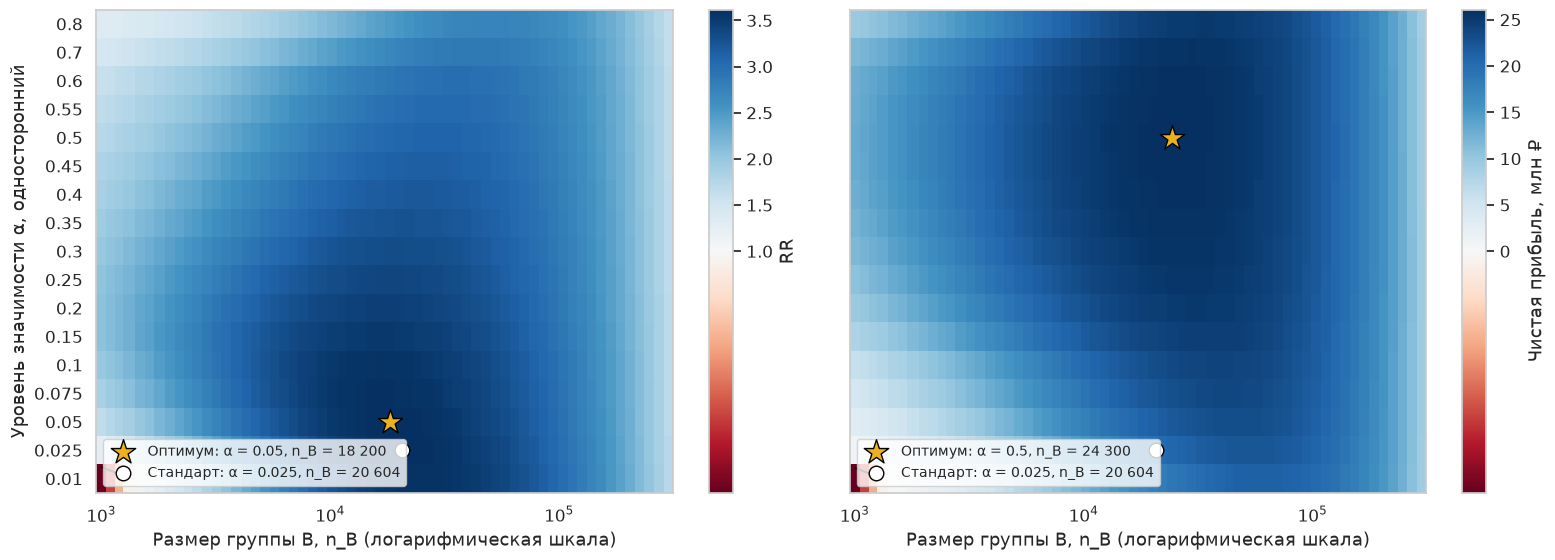

In [7]:
grid = design_grid(case)
p, mde, s = case.baseline_cr, 0.01, case.share_b
n_standard = int(np.ceil((norm.ppf(0.975) + norm.ppf(0.8)) ** 2 * p * (1 - p) * (1 + s / (1 - s)) / mde ** 2))
plot_design_maps(grid, {f'Стандарт: α = 0.025, n_B = {spaced(n_standard)}': (0.025, n_standard)})

In [8]:
rr_alpha, rr_n, *_ = best_design(grid, 'rr')
net_alpha, net_n, *_ = best_design(grid, 'net')

designs = {  # название: (alpha, n_B, порог решения)
    'Стандарт: против нуля': (0.025, n_standard, 0.0),
    'Максимум RR': (rr_alpha, rr_n, case.break_even),
    'Максимум прибыли': (net_alpha, net_n, case.break_even),
}
rows = {'Ничего не делать': {'α': np.nan, 'n_B': np.nan, 'Дней': 0, 'Прибыль, млн ₽': 0.0, 'RR': np.nan},
        'Внедрить без теста': {'α': np.nan, 'n_B': np.nan, 'Дней': 0,
                               'Прибыль, млн ₽': ship_without_test(case, effect_grid, density) / 1e6, 'RR': np.nan}}
for name, (alpha, n_b, threshold) in designs.items():
    result = evaluate_design(case, effect_grid, density, n_b, alpha, threshold)
    rows[name] = {'α': alpha, 'n_B': n_b, 'Дней': case.test_weeks(n_b) * 7,
                  'Прибыль, млн ₽': result['net'] / 1e6, 'RR': result['rr']}
comparison = pd.DataFrame(rows).T.astype(float)
comparison.round({'α': 3, 'n_B': 0, 'Дней': 1, 'Прибыль, млн ₽': 2, 'RR': 2})

,α,n_B,Дней,"Прибыль, млн ₽",RR
Ничего не делать,NaN,NaN,0.0,0.00,NaN
Внедрить без теста,NaN,NaN,0.0,2.75,NaN
Стандарт: против нуля,0.025,20604.0,13.7,23.22,3.57
Максимум RR,0.050,18200.0,12.1,20.99,3.62
Максимум прибыли,0.500,24300.0,16.2,26.09,3.09


Что видно:

* **Оптимум внутри сетки:** $\alpha = 0.5$, $n_B = 24.3$ тыс., 16 дней, 26.1 млн ₽. Дольше — потери от отложенного внедрения перевешивают точность.
* **Честный стандарт неплох:** 23.2 млн ₽ за 14 дней. Он проигрывает 2.9 млн ₽ только строгим порогом.
* **RR и прибыль выбирают разное.** Максимум RR ($\alpha = 0.05$, 12 дней) теряет 5 млн ₽ прибыли.
* **Без теста** — всего 2.75 млн ₽: в плюс выводит только откат крупных провалов. Тест добавляет ещё 23 млн ₽ за счёт отбора вариантов.

Sunk cost, зависимость RR от разнесения статей и прибыль на неделю теста — в `lesson.ipynb`, раздел «Поиск оптимальных α и n». Там же — демо со слайдерами, где оптимум пересчитывается для других ожиданий и бизнес-параметров.

## Блок 4. $\alpha = 0.5$ — не монетка

**Тезис.** $\alpha$ — вероятность внедрения при эффекте ровно на пороге, а не доля ошибочных решений. Тест с $\alpha = 0.5$ против нуля внедряет вариант, если оценка эффекта положительна, и его шанс растёт с эффектом. Монетка внедряет с вероятностью 50% что угодно.

Для простоты сравним с нулём ($\theta_{BE} = 0$) и без денег.

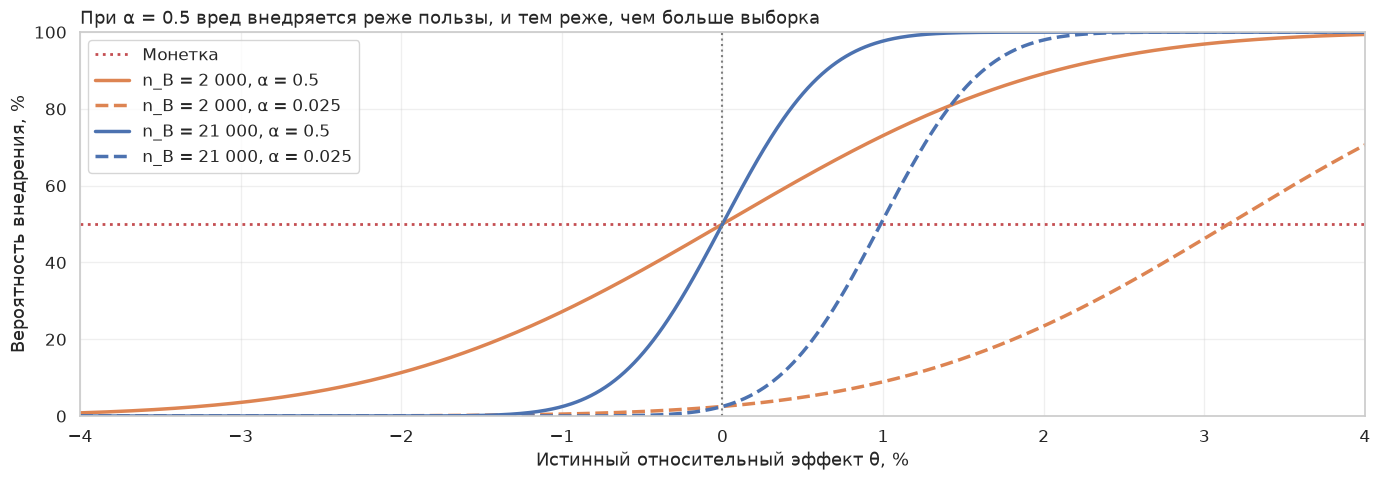

,Доля внедрений,Доля вредных среди внедрённых,"Средний эффект на решение, %"
Монетка,0.500,0.499,0.000
"n_B = 2 000, α = 0.025",0.075,0.049,0.145
"n_B = 2 000, α = 0.5",0.501,0.263,0.404
"n_B = 21 000, α = 0.025",0.267,0.005,0.468
"n_B = 21 000, α = 0.5",0.500,0.102,0.567


In [9]:
def rollout_quality(n_b: int, alpha: float) -> pd.Series:
    """Доля внедрений, доля вредных среди внедрённых и средний эффект на решение для ожиданий π(θ)."""
    if alpha is None:   # монетка
        probability = np.full_like(effect_grid, 0.5)
    else:
        probability = implementation_probability(case.baseline_cr, effect_grid, 0.0, n_b, alpha, case.share_b)
    p_ship = np.trapezoid(probability * density, effect_grid)
    p_bad = np.trapezoid(probability * density * (effect_grid < 0), effect_grid)
    return pd.Series({'Доля внедрений': p_ship, 'Доля вредных среди внедрённых': p_bad / p_ship,
                      'Средний эффект на решение, %': np.trapezoid(effect_grid * probability * density, effect_grid) * 100})


fig, ax = plt.subplots(figsize=(14, 5))
ax.axhline(50, color=RED, linewidth=2, linestyle=':', label='Монетка')
for n_b, color in [(2_000, ORANGE), (21_000, BLUE)]:
    for alpha, style in [(0.5, '-'), (0.025, '--')]:
        probability = implementation_probability(case.baseline_cr, effect_grid, 0.0, n_b, alpha, case.share_b)
        ax.plot(effect_grid * 100, probability * 100, color=color, linestyle=style, linewidth=2.5,
                label=f'n_B = {spaced(n_b)}, α = {alpha}')
ax.axvline(0, color=GRAY, linestyle=':', linewidth=1.5)
ax.set_title('При α = 0.5 вред внедряется реже пользы, и тем реже, чем больше выборка', loc='left')
ax.set_xlabel('Истинный относительный эффект θ, %')
ax.set_ylabel('Вероятность внедрения, %')
ax.set_xlim(-4, 4)
ax.set_ylim(0, 100)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

pd.DataFrame({
    'Монетка': rollout_quality(0, None),
    'n_B = 2 000, α = 0.025': rollout_quality(2_000, 0.025),
    'n_B = 2 000, α = 0.5': rollout_quality(2_000, 0.5),
    'n_B = 21 000, α = 0.025': rollout_quality(21_000, 0.025),
    'n_B = 21 000, α = 0.5': rollout_quality(21_000, 0.5),
}).T.round(3)

* **Монетка** внедряет половину вариантов, половина внедрённых вредна, средний эффект — ноль.
* **$\alpha = 0.5$** внедряет столько же, но вредных среди внедрённых меньше: 26% при $n_B = 2\,000$ и 10% при $n_B = 21\,000$. Средний эффект на решение положителен.
* **Строгий $\alpha$** почти не пускает вред, но и пользу пропускает: средний эффект ниже.

От плохих внедрений при высоком $\alpha$ защищает только выборка.

**Почему $\alpha = 0.5$ — не новая норма.** Строгость нашего вердикта спрятана не в $\alpha$, а в пороге: решаем против BE = 0.25 п.п., а не против нуля. В привычных терминах теста против нуля правило «оценка выше 0.25 п.п.» при $n_B = 21\,000$ — это одностороннее $\alpha \approx 0.24$: вариант без эффекта внедряется в 24% случаев. Среди внедрённых 13% не окупаются и 4.5% вредны.

Оптимум держится у 0.5, потому что ошибка здесь дешёвая и обратимая, а модель смотрит только на среднюю прибыль. Для необратимого решения или пессимистичных ожиданий пересчитайте. И никогда не переносите «$\alpha = 0.5$» в тест против нуля.

## Итоги

* Успех теста — эффект выше точки безубыточности; у нас это 0.35%, или 0.25 п.п.
* Решение принимаем против BE; $\alpha$ и $n$ — ручки, которые двигают деньги, а не соглашение.
* Модель обязана учитывать цену времени (тест откладывает внедрение) и согласованный откат.
* RR зависит от разнесения статей, прибыль — нет. Для портфеля — прибыль на неделю трафика.
* $\alpha = 0.5$ имеет смысл только вместе с порогом BE; против нуля наш вердикт — $\alpha \approx 0.24$.
* На практике соберём вердикт: BE → вероятность внедрения → сетка → «тестируем / нет» с итоговыми $\alpha$ и $n$.